In [1]:
%mamba install pandas
%mamba install scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.144 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.0.6    np23py313h124dbc7_0  emscripten-forge-4x
+ python-tzdata  2026.4   pyh5ded981_0         conda-forge
- pip            26.2.1   pyh145f28c_0         conda-forge
mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.178 seconds
  Name                Version    Build                Channel
---------------------------------------------------------------------------
+ brotli-python       1.2.0      py313ha26e73d_2      emscripten-forge-4x
+ certifi             2026.7.22  pyhd8ed1ab_0         conda-f

Silhouette Score: 0.62


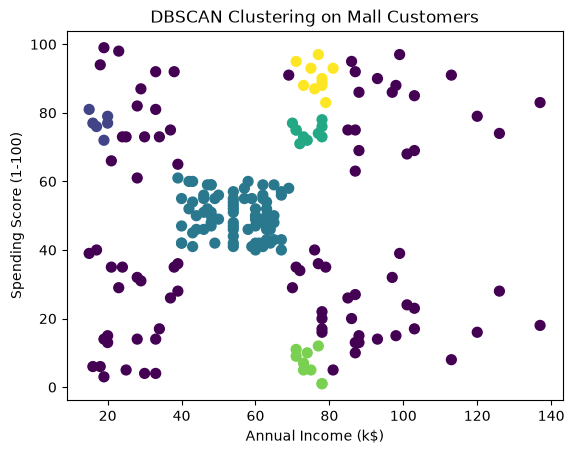

Cluster Labels:
[-1  0 -1  0 -1  0 -1 -1 -1  0 -1 -1 -1  0 -1  0 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1 -1 -1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1 -1 -1  2 -1  4  3  2  3  2 -1  2  3  4  3  2  3  2  3  4 -1  4
  3  4 -1  2 -1  4 -1  4 -1  2 -1  4  3  2  3  2 -1  4 -1  4 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1]

Number of clusters: 5
Number of noise points: 87


In [2]:
# EXP 16 - DBSCAN Clustering using Mall_Customers.csv

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, confusion_matrix

# Load the dataset
data = pd.read_csv("Mall_Customers.csv")

# Select features for clustering
X = data[['Annual Income (k$)', 'Spending Score (1-100)']]

# Apply DBSCAN clustering
dbscan = DBSCAN(eps=5, min_samples=5)
y_dbscan = dbscan.fit_predict(X)

# Calculate silhouette score
# Silhouette score cannot be calculated if DBSCAN produces only one cluster
mask = y_dbscan != -1

if len(set(y_dbscan[mask])) > 1:
    sil_score = silhouette_score(X[mask], y_dbscan[mask])
    print(f"Silhouette Score: {sil_score:.2f}")
else:
    sil_score = None
    print("Silhouette Score cannot be calculated.")

# Plot the clusters
plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=y_dbscan,
    cmap='viridis',
    s=50
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('DBSCAN Clustering on Mall Customers')
plt.show()

# Print cluster information
print("Cluster Labels:")
print(y_dbscan)

print("\nNumber of clusters:", len(set(y_dbscan)) - (1 if -1 in y_dbscan else 0))
print("Number of noise points:", list(y_dbscan).count(-1))